# LBM D1Q3 quantique — advection-diffusion : block-encoding de la collision $C$ et circuit du streaming $S$

**Objectif.** Reprendre la chaîne du cas diffusif (`LBM_D1Q3_Circuit_tot.ipynb`) avec l'**équilibre d'ordre 1 en $u$**
$$f^{eq}_a=\omega_a\,\rho\Big(1+\frac{c_a\,u}{c_s^2}\Big),\qquad u=\frac{\sum_b c_b f_b}{\rho},$$
où la vitesse $u$ est **recalculée à partir des $f$**, en chaque nœud et à chaque pas : elle n'est pas imposée. Le schéma reste $F^{n+1}=S\,C\,F^n$.

**Ce qu'il faut retenir** (démontré en partie 1) :
- comme $\rho\,u=j$, l'équilibre est **linéaire** en $f$ : $f^{eq}=E\,f$, avec $E$ une matrice $3\times3$ constante. La collision reste donc $C=C_{loc}\otimes I_N$ et se block-encode exactement comme en diffusion ;
- la collision conserve la **masse** $\rho$ **et le flux** $j$. Le transport se fait à la vitesse du son $c_s=1/\sqrt3$ ;
- une **onde progressive** ($j=c_s\,\delta\rho$) obéit à l'équation d'**advection-diffusion** $\partial_t\delta\rho+c_s\,\partial_x\delta\rho=\Gamma\,\partial_{xx}\delta\rho$, avec $\Gamma=\tfrac12(1-c_s^2)(\tau-\tfrac12)$.

| Opérateur | Unitaire ? | Ce qu'on fait |
|---|---|---|
| $C$ (collision) | **non** | on la **block-encode** avec FABLE (méthode de `block_encoding.ipynb`) |
| $S$ (streaming) | **oui** (permutation) | circuit **exact** d'incréments contrôlés : pas besoin de FABLE |

Plan :
1. matrices classiques avec l'équilibre d'ordre 1 ($E$, $C$, $S$), équation macroscopique et condition initiale (ordre des directions $(0,-,+)$) ;
2. passage à une taille $2^n$ : on ajoute une 4ᵉ direction vide ($3N \to 4N$), ce qui modifie $C$ **et** $S$ ;
3. block-encoding de $C$ avec FABLE → matrice block-encodée + circuit ;
4. version optimisée : $C = C_{loc}\otimes I_N$, on ne block-encode que $C_{loc}$ ($4\times4$) ;
5. circuit de $S$ ;
6. un pas complet $S\,C$ en circuit ;
7. circuit complet (préparation, $T$ pas, mesures) comparé au LBM classique et à la solution analytique d'advection-diffusion ;
8. bonus : dilatation minimale de $C_{loc}$ (1 seul ancilla).

Requiert `numpy`, `scipy`, `matplotlib`, `qiskit`, `qiskit-aer`, `fable-circuits`.

## 0. Outils repris de `block_encoding.ipynb`

Rappel : $U$ est un block-encoding de $A$ si, en mettant les $m$ ancillas dans $|0^m\rangle$, en
appliquant $U$ puis en projetant les ancillas sur $|0^m\rangle$, on obtient $A$ (à un facteur près) :
$$U = \begin{bmatrix} A/(\alpha N_A) & \cdot \\ \cdot & \cdot \end{bmatrix},
\qquad A = \alpha\,N_A\,\big(\langle 0^m|\otimes I\big)\,U\,\big(|0^m\rangle\otimes I\big).$$

Pour FABLE, `circ, alpha = fable(A, eps)` renvoie un circuit à $2n+1$ qubits ($A$ de taille
$N_A = 2^n$) et le facteur `alpha`. Le bloc en haut à gauche de $U$ vaut $A/(\alpha N_A)$.
Les fonctions ci-dessous sont reprises telles quelles du notebook.

In [56]:
import numpy as np
import scipy.linalg as sl
import matplotlib.pyplot as plt
from fable import fable
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Operator, Statevector
from qiskit.circuit.library import UnitaryGate
from qiskit_aer import Aer

simulator = Aer.get_backend("unitary_simulator")

def block_encoding(A, eps=1e-6):
    # FABLE block-encoding of A, returned with a check of the relation.
    # Returns (circuit, alpha, unitary, relative_error).
    N = A.shape[0]
    circ, alpha = fable(A, eps)
    U = simulator.run(circ).result().get_unitary(circ)
    # leading N x N block should be A / (alpha * N)
    block = U.data[:N, :N]
    err = np.linalg.norm(alpha * N * block - A) / np.linalg.norm(A)
    return circ, alpha, U, err

def circuit_stats(circ):
    ops = circ.count_ops()
    return circ.num_qubits, circ.depth(), sum(ops.values())

print("setup ok")

setup ok


## 1. Les matrices classiques (notations du tableau)

- directions $a \in \{0,-,+\}$, poids $\omega = (2/3,\ 1/6,\ 1/6)$, vitesses $c=(0,-1,+1)$, $c_s^2=\sum_a\omega_a c_a^2=1/3$ ;
- nœuds $i \in \{0,\dots,N-1\}$ ; $F^n = (f^n_0,\ f^n_-,\ f^n_+) \in \mathbb{R}^{3N}$, la composante $(a,i)$ est à la position $a\cdot N + i$ ;
- au nœud $i$ : $\rho_i=\sum_a f_{a,i}$, $\ j_i=\sum_a c_a f_{a,i}=f_{+,i}-f_{-,i}$, $\ u_i=j_i/\rho_i$.

**Équilibre en fonction des $f$.** Comme $\rho_i u_i=j_i$, la division par $\rho$ disparaît :
$$f^{eq}_{a,i}=\omega_a\,\rho_i+\frac{\omega_a c_a}{c_s^2}\,j_i
\quad\Longleftrightarrow\quad f^{eq}_{\cdot,i}=E\,f_{\cdot,i},\qquad
E=\omega\,\mathbf 1^{T}+\frac{(\omega\circ c)\,c^{T}}{c_s^2}=\begin{pmatrix}2/3&2/3&2/3\\1/6&2/3&-1/3\\1/6&-1/3&2/3\end{pmatrix}.$$
Propriétés : $\mathbf 1^{T}E=\mathbf 1^{T}$ (masse conservée), $c^{T}E=c^{T}$ (flux conservé), $E^2=E$.

**Collision et streaming.**
$$C=\Big(1-\frac1\tau\Big)I_{3N}+\frac1\tau\,E\otimes I_N=C_{loc}\otimes I_N,\qquad C_{loc}=\Big(1-\frac1\tau\Big)I_3+\frac{E}{\tau},$$
$$S = \begin{pmatrix} I_N & & \\ & P^- & \\ & & P^+\end{pmatrix}, \qquad (P^+v)_i = v_{i-1},\quad P^- = (P^+)^T.$$
Différence avec la diffusion pure, où $E_{\rm diff}=\omega\,\mathbf 1^{T}$ : le terme $(\omega\circ c)\,c^{T}/c_s^2$ ajoute la conservation de $j$.

**Équation macroscopique** (Chapman-Enskog, ordre 2) :
$$\partial_t\rho+\partial_x j=0,\qquad \partial_t j+c_s^2\,\partial_x\rho=\nu\,\partial_{xx}j,\qquad \nu=(1-c_s^2)\Big(\tau-\frac12\Big).$$
Un mode $e^{ikx}$ se propage à $\pm c_s$ et décroît en $e^{-\Gamma k^2 t}$, avec $\Gamma=\nu/2$. Pour une **onde progressive vers la droite** ($j=c_s\,\delta\rho$), la perturbation $\delta\rho$ suit donc
$$\partial_t\delta\rho+c_s\,\partial_x\delta\rho=\Gamma\,\partial_{xx}\delta\rho .$$
C'est l'équation d'**advection-diffusion** étudiée ici. La vitesse d'advection vaut $c_s$ : elle est fixée par le réseau, ce n'est pas un paramètre libre.

**Condition initiale.** $\rho^0=\bar\rho+\delta\rho^0$ (fond constant + gaussienne), $j^0=c_s\,\delta\rho^0$, et $F^0=f^{eq}(\rho^0,j^0)$. Le fond $\bar\rho=1$ garantit $f\ge0$, ce qui est indispensable à la reconstruction $f\propto\sqrt{P}$ de la partie 7 : avec $\bar\rho=0$, on aurait $f^0_-<0$.

On prend $N = 8$ nœuds ($3$ qubits de position) et $\tau = 0.8$.

In [57]:
tau = 0.8
k = 3                      # nombre de qubits de position
N = 2**k                   # nombre de noeuds

w   = np.array([2/3, 1/6, 1/6])      # poids D1Q3, ordre (0, -, +)
c   = np.array([0, -1, +1])          # vitesses discretes a x 1
cs2 = (w*c**2).sum()                 # c_s^2 = 1/3
cs  = np.sqrt(cs2)                   # vitesse du son = vitesse d'advection de l'onde progressive
nu  = (1 - cs2)*(tau - 0.5)          # viscosite de l'equation sur j
Gam = nu/2                           # coefficient de diffusion de l'onde progressive

# equilibre d'ordre 1 avec u = j/rho :  f^eq = E f  au noeud i
E = np.outer(w, np.ones(3)) + np.outer(w*c, c)/cs2                 # 3 x 3
np.set_printoptions(precision=3, suppress=True)
print("E =\n", E)
print("1^T E = 1^T (masse)  :", np.allclose(E.sum(axis=0), 1))
print("c^T E = c^T (flux)   :", np.allclose(c @ E, c))
print("E^2 = E (projecteur) :", np.allclose(E @ E, E))

I_N = np.eye(N)
C_loc = (1 - 1/tau)*np.eye(3) + E/tau                              # 3 x 3
C = (1 - 1/tau)*np.eye(3*N) + np.kron(E, I_N)/tau                  # 3N x 3N (ordre direction par direction)
print("C = C_loc (x) I_N :", np.allclose(C, np.kron(C_loc, I_N)))
print("colonnes de C_loc de somme 1 (masse) :", np.allclose(C_loc.sum(axis=0), 1))

P_plus = np.roll(I_N, 1, axis=0)        # (P+ v)_i = v_{i-1}
P_minus = P_plus.T
Z = np.zeros((N, N))
S = np.block([[I_N, Z, Z],
              [Z, P_minus, Z],
              [Z, Z, P_plus]])          # 3N x 3N
print("P+ @ (0,1,...,N-1) =", P_plus @ np.arange(N))
print("S unitaire :", np.allclose(S.T @ S, np.eye(3*N)))
print("C unitaire :", np.allclose(C.T @ C, np.eye(3*N)))
print("C_loc =\n", C_loc)
print(f"c_s = {cs:.4f}   nu = {nu:.4f}   Gamma = {Gam:.4f}")

E =
 [[ 0.667  0.667  0.667]
 [ 0.167  0.667 -0.333]
 [ 0.167 -0.333  0.667]]
1^T E = 1^T (masse)  : True
c^T E = c^T (flux)   : True
E^2 = E (projecteur) : True
C = C_loc (x) I_N : True
colonnes de C_loc de somme 1 (masse) : True
P+ @ (0,1,...,N-1) = [7. 0. 1. 2. 3. 4. 5. 6.]
S unitaire : True
C unitaire : False
C_loc =
 [[ 0.583  0.833  0.833]
 [ 0.208  0.583 -0.417]
 [ 0.208 -0.417  0.583]]
c_s = 0.5774   nu = 0.2000   Gamma = 0.1000


**Vérification** : $F^{n+1} = S\,C\,F^n$ redonne exactement le LBM « boucle » : calcul de $\rho$ et de $j=\rho u$, collision BGK vers $f^{eq}$, puis `np.roll`.
On construit aussi la condition initiale (onde progressive sur un fond $\bar\rho=1$, cf. ci-dessus) et on vérifie que les populations sont positives.

In [58]:
def f_eq(rho, j):
    # f^eq_{a,i} = w_a rho_i + w_a c_a j_i / cs^2   (= w_a rho_i (1 + c_a u_i / cs^2) avec u_i = j_i / rho_i)
    # ecrit sans division par rho
    return w[:, None]*rho + (w*c/cs2)[:, None]*j

def lbm_step_loop(f):
    # f de forme (3, N), ordre (0, -, +) : collision BGK puis streaming
    rho = f.sum(axis=0)              # densite
    j = c @ f                        # flux j = rho u
    fs = f - (f - f_eq(rho, j))/tau
    return np.stack([fs[0], np.roll(fs[1], -1), np.roll(fs[2], +1)])

x = np.arange(N)
rho_bar, A0, sigma0, x0 = 1.0, 1.0, 1.5, N/2
drho0 = A0*np.exp(-(x - x0)**2/(2*sigma0**2))     # perturbation gaussienne
rho0 = rho_bar + drho0                             # densite initiale
j0 = cs*drho0                                      # onde progressive vers la droite
f0 = f_eq(rho0, j0)                                # initialisation a l'equilibre, forme (3, N)
print("u initiale = j/rho : min", round((j0/rho0).min(), 3), "  max", round((j0/rho0).max(), 3))
print("min f0 =", round(f0.min(), 4), " (>= 0)")

f = f0.copy()
F = f0.reshape(-1)                                 # F^0 in R^{3N}
for _ in range(5):
    f = lbm_step_loop(f)
    F = S @ C @ F
print("max |F_matriciel - F_boucle| =", np.abs(F - f.reshape(-1)).max())

u initiale = j/rho : min 0.016   max 0.289
min f0 = 0.0447  (>= 0)
max |F_matriciel - F_boucle| = 4.440892098500626e-16


## 2. Passage à une taille $2^n$ : $3N \to 4N$

Un registre de $q$ qubits contient $2^q$ amplitudes. $3N$ n'est pas une puissance de 2, on ajoute donc
une **4ᵉ direction fictive** « $\varnothing$ », toujours vide :
$$F^n = (f^n_0,\ f^n_-,\ f^n_+,\ \underbrace{0}_{f_\varnothing}) \in \mathbb{R}^{4N},
\qquad |F^n\rangle = \sum_{a,i} f^n_{a,i}\,|a\rangle_{\text{dir}}\,|i\rangle_{\text{pos}}$$
avec **2 qubits de direction** et $k=\log_2 N$ **qubits de position** ($4N = 2^{k+2}$).

C'est là que **$C$ et $S$ changent de forme** (mais pas de physique) :

$$C_4 = C_{loc,4}\otimes I_N,\quad C_{loc,4} = \begin{pmatrix} C_{loc} & 0 \\ 0 & 0\end{pmatrix}\ (4\times4),
\qquad
S_4 = \begin{pmatrix} I_N &&& \\ & P^- && \\ && P^+ & \\ &&& I_N\end{pmatrix}\ (4N\times4N).$$

- dans $C_4$ la direction $\varnothing$ est mise à 0 (elle ne reçoit rien) ;
- dans $S_4$ on met $I_N$ sur la direction $\varnothing$ pour que $S_4$ **reste unitaire**.

In [59]:
C_loc4 = np.zeros((4, 4)); C_loc4[:3, :3] = C_loc
C4 = np.kron(C_loc4, I_N)                                   # 4N x 4N
S4 = np.block([[I_N, Z, Z, Z],
               [Z, P_minus, Z, Z],
               [Z, Z, P_plus, Z],
               [Z, Z, Z, I_N]])                             # 4N x 4N
D = 4*N
print("taille :", C4.shape, "=", f"2^{int(np.log2(D))}")
print("S4 unitaire :", np.allclose(S4.T @ S4, np.eye(D)))
print("le bloc 3N x 3N de S4 C4 est S C :", np.allclose((S4 @ C4)[:3*N, :3*N], S @ C))

taille : (32, 32) = 2^5
S4 unitaire : True
le bloc 3N x 3N de S4 C4 est S C : True


**Convention Qiskit** (little-endian) : l'indice $a\cdot N + i$ d'un vecteur de $2^{k+2}$ amplitudes
s'écrit en binaire avec les bits de poids faible = position $i$ et les 2 bits de poids fort = direction $a$.
Donc **qubits $0,\dots,k-1$ = position** et **qubits $k, k+1$ = direction**, codée
$0 \to |00\rangle$, $- \to |01\rangle$, $+ \to |10\rangle$, $\varnothing \to |11\rangle$
(notation $|q_{k+1}q_k\rangle$).

## 3. Block-encoding de $C$ avec FABLE (matrice complète $4N\times4N$)

On applique directement la méthode de `block_encoding.ipynb` à $C_4$.

In [60]:
circ_C, alpha_C, U_C, err_C = block_encoding(C4)
nq, depth, gates = circuit_stats(circ_C)
print(f"C4 : {D}x{D}  ({k+2} qubits systeme)")
print(f"circuit : {nq} qubits ({k+2} systeme + {nq-(k+2)} ancillas), profondeur {depth}, {gates} portes")
print(f"alpha = {alpha_C:.4f}")
print(f"facteur total alpha * D = {alpha_C*D:.1f}   ->   bloc haut-gauche de U = C4 / {alpha_C*D:.0f}")
print(f"erreur relative du block-encoding = {err_C:.3e}")

C4 : 32x32  (5 qubits systeme)
circuit : 11 qubits (5 systeme + 6 ancillas), profondeur 286, 299 portes
alpha = 1.0000
facteur total alpha * D = 32.0   ->   bloc haut-gauche de U = C4 / 32
erreur relative du block-encoding = 1.365e-15


**La matrice block-encodée** : $U$ est un unitaire $2^{2(k+2)+1}\times 2^{2(k+2)+1}$. Son bloc
haut-gauche $D\times D$ (ancillas dans $|0\rangle$) est $C_4/(\alpha D)$ :

U unitaire : True
taille de U : (2048, 2048)


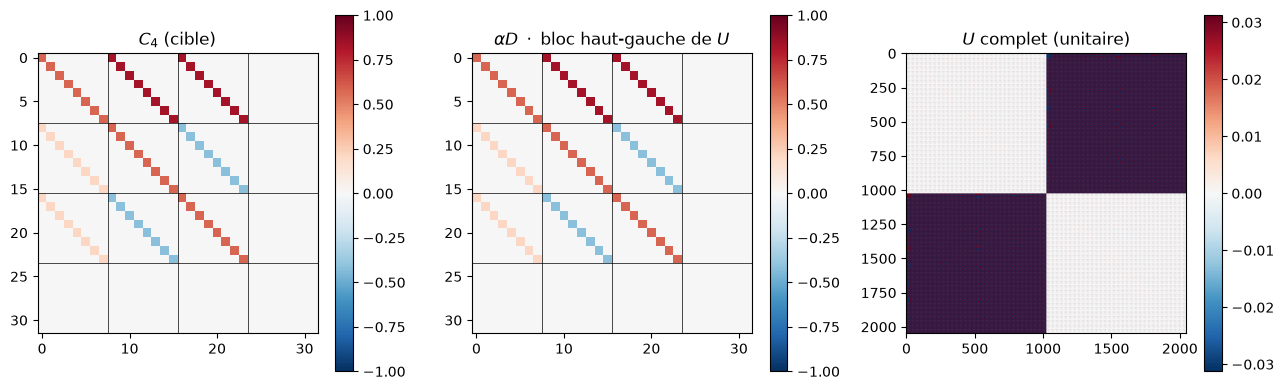

In [61]:
block_C = U_C.data[:D, :D]
print("U unitaire :", np.allclose(U_C.data.conj().T @ U_C.data, np.eye(U_C.data.shape[0])))
print("taille de U :", U_C.data.shape)

fig, ax = plt.subplots(1, 3, figsize=(13, 4))
im = ax[0].imshow(C4, cmap='RdBu_r', vmin=-1, vmax=1); ax[0].set_title(r'$C_4$ (cible)')
plt.colorbar(im, ax=ax[0])
im = ax[1].imshow(np.real(alpha_C*D*block_C), cmap='RdBu_r', vmin=-1, vmax=1)
ax[1].set_title(r'$\alpha D\ \cdot$ bloc haut-gauche de $U$'); plt.colorbar(im, ax=ax[1])
im = ax[2].imshow(np.real(U_C.data), cmap='RdBu_r'); ax[2].set_title(r'$U$ complet (unitaire)')
plt.colorbar(im, ax=ax[2])
for a in ax[:2]:
    for t in (N, 2*N, 3*N):
        a.axhline(t-0.5, color='k', lw=0.5); a.axvline(t-0.5, color='k', lw=0.5)
plt.tight_layout(); plt.show()

Le circuit FABLE (rotations $R_y$ + CNOT) est long : on affiche sa composition et ses 20 premières portes.

In [62]:
print("portes :", dict(circ_C.count_ops()))
debut = QuantumCircuit(circ_C.num_qubits)
for inst in circ_C.data[:20]:
    debut.append(inst)
print("20 premieres portes :")
print(debut.draw(output='text', fold=120))

portes : {'cx': 156, 'ry': 128, 'h': 10, 'swap': 5}
20 premieres portes :
      ┌────────────┐┌───┐┌──────────────┐┌───┐┌──────────────┐┌───┐┌──────────────┐┌───┐┌───┐┌──────────────┐┌───┐»
 q_0: ┤ Ry(3.0885) ├┤ X ├┤ Ry(-0.01629) ├┤ X ├┤ Ry(0.020527) ├┤ X ├┤ Ry(-0.01629) ├┤ X ├┤ X ├┤ Ry(-0.01629) ├┤ X ├»
      └───┬───┬────┘└─┬─┘└──────────────┘└─┬─┘└──────────────┘└─┬─┘└──────────────┘└─┬─┘└─┬─┘└──────────────┘└─┬─┘»
 q_1: ────┤ H ├───────┼────────────────────┼────────────────────┼────────────────────┼────┼────────────────────┼──»
          ├───┤       │                    │                    │                    │    │                    │  »
 q_2: ────┤ H ├───────┼────────────────────┼────────────────────┼────────────────────┼────┼────────────────────┼──»
          ├───┤       │                    │                    │                    │    │                    │  »
 q_3: ────┤ H ├───────┼────────────────────┼────────────────────┼────────────────────┼────┼────────────────────┼──

## 4. Mieux : block-encoder seulement $C_{loc}$ ($4\times4$)

Comme $C_4 = C_{loc,4}\otimes I_N$, la collision **n'agit que sur les 2 qubits de direction** et laisse
les qubits de position intacts. Il suffit donc de block-encoder $C_{loc,4}$ et d'appliquer ce petit
circuit sur les qubits de direction :

$$U_{C_4} = U_{C_{loc}} \otimes I_N \quad\Rightarrow\quad
\text{bloc haut-gauche} = \frac{C_{loc,4}}{4\alpha}\otimes I_N = \frac{C_4}{4\alpha}.$$

Avantages : circuit **indépendant de $N$**, et facteur de normalisation $4\alpha$ au lieu de $4N\alpha$.

In [63]:
circ_loc, alpha_loc, U_loc, err_loc = block_encoding(C_loc4)
nq, depth, gates = circuit_stats(circ_loc)
print(f"C_loc4 : 4x4 (2 qubits)")
print(f"circuit : {nq} qubits (2 systeme + {nq-2} ancillas), profondeur {depth}, {gates} portes")
print(f"alpha = {alpha_loc:.4f}, facteur total = {alpha_loc*4:.1f}")
print(f"erreur relative = {err_loc:.3e}")
print("bloc 4x4 * 4 alpha =\n", np.real(alpha_loc*4*U_loc.data[:4, :4]))
print("\ncomparaison avec FABLE sur C4 complet :")
print(f"  portes     : {circuit_stats(circ_C)[2]}  ->  {gates}")
print(f"  facteur    : {alpha_C*D:.0f}  ->  {alpha_loc*4:.0f}")

C_loc4 : 4x4 (2 qubits)
circuit : 5 qubits (2 systeme + 3 ancillas), profondeur 34, 38 portes
alpha = 1.0000, facteur total = 4.0
erreur relative = 3.706e-16
bloc 4x4 * 4 alpha =
 [[ 0.583  0.833  0.833  0.   ]
 [ 0.208  0.583 -0.417  0.   ]
 [ 0.208 -0.417  0.583  0.   ]
 [ 0.     0.     0.     0.   ]]

comparaison avec FABLE sur C4 complet :
  portes     : 299  ->  38
  facteur    : 32  ->  4


In [64]:
print(circ_loc.draw(output='text', fold=120))

                                                                                                         »
q_0: ────────────────■────────────────────────────────────────■───────────────────────────────────────■──»
                     │                                        │                                       │  »
q_1: ────────────────┼────────────────────■───────────────────┼───────────────────────────────────────┼──»
         ┌───┐       │                    │                   │                                       │  »
q_2: ────┤ H ├───────┼────────────────────┼───────────────────┼────────────────────■──────────────────┼──»
         ├───┤       │                    │                   │                    │                  │  »
q_3: ────┤ H ├───────┼────────────────────┼───────────────────┼────────────────────┼──────────────────┼──»
     ┌───┴───┴────┐┌─┴─┐┌──────────────┐┌─┴─┐┌─────────────┐┌─┴─┐┌──────────────┐┌─┴─┐┌────────────┐┌─┴─┐»
q_4: ┤ Ry(2.7167) ├┤ X ├┤ Ry(-0.13032

Dans ce circuit, `q_0, q_1` sont les qubits système (ici : la direction) et `q_2, q_3, q_4` les ancillas.

## 5. Circuit du streaming $S_4$

$S_4$ est une **permutation**, donc déjà unitaire : on n'a **pas besoin** de la block-encoder.
On la construit exactement :

- direction $-$ (état $|01\rangle$) : $i \to i-1$ sur les qubits de position = **décrément** $P^-$ ;
- direction $+$ (état $|10\rangle$) : $i \to i+1$ = **incrément** $P^+$ ;
- directions $0$ et $\varnothing$ : rien.

L'incrément modulo $2^k$ se fait avec une cascade de portes multi-contrôlées (le bit $j$ bascule si
tous les bits de poids plus faible valent 1). Le décrément est son inverse.

In [65]:
def increment(m):
    # |i> -> |i+1 mod 2^m>  (= P+)
    qc = QuantumCircuit(m, name="+1")
    for j in reversed(range(m)):
        if j == 0:
            qc.x(0)
        else:
            qc.mcx(list(range(j)), j)
    return qc

inc = increment(k)
print("increment = P+ :", np.allclose(Operator(inc).data, P_plus))

pos = list(range(k)); dirq = [k, k+1]
circ_S = QuantumCircuit(k+2, name="S")
# ctrl_state s'ecrit |q_{k+1} q_k> : '01' = direction '-', '10' = direction '+'
circ_S.append(inc.inverse().to_gate(label="P-").control(2, ctrl_state='01'), dirq + pos)
circ_S.append(inc.to_gate(label="P+").control(2, ctrl_state='10'), dirq + pos)
print("circuit = S4 :", np.allclose(Operator(circ_S).data, S4))
print(circ_S.draw(output='text'))

increment = P+ : True
circuit = S4 : True
     ┌─────┐┌─────┐
q_0: ┤0    ├┤0    ├
     │     ││     │
q_1: ┤1 P- ├┤1 P+ ├
     │     ││     │
q_2: ┤2    ├┤2    ├
     └──┬──┘└──┬──┘
q_3: ───■──────o───
        │      │   
q_4: ───o──────■───
                   


**Pourquoi pas FABLE pour $S$ ?** FABLE marche sur n'importe quelle matrice, mais il la
*sous-normalise* : le bloc vaut $S_4/(\alpha D)$. On ne récupèrerait $S_4$ qu'avec une probabilité
$\sim 1/(\alpha D)^2$, alors que le circuit exact l'applique avec probabilité 1.

In [66]:
circ_S_fable, alpha_S, U_S, err_S = block_encoding(S4)
print(f"FABLE sur S4 : {circuit_stats(circ_S_fable)[2]} portes, facteur {alpha_S*D:.0f} "
      f"-> probabilite de succes ~ 1/{(alpha_S*D)**2:.0f}")
t = transpile(circ_S, basis_gates=['cx', 'u'], optimization_level=1)
print(f"circuit exact   : {sum(t.count_ops().values())} portes (cx+u), facteur 1 -> probabilite 1")

FABLE sur S4 : 533 portes, facteur 32 -> probabilite de succes ~ 1/1024
circuit exact   : 659 portes (cx+u), facteur 1 -> probabilite 1


## 6. Un pas complet $F^{n+1} = S_4\,C_4\,F^n$ en circuit

On enchaîne le block-encoding de la collision (sur les qubits de direction + 3 ancillas) puis $S_4$
(sur direction + position). Les ancillas sont les qubits de poids fort : le bloc haut-gauche
$D\times D$ du circuit total vaut
$$\frac{S_4\,C_4}{4\alpha}.$$

In [67]:
n_anc = circ_loc.num_qubits - 2
anc = list(range(k+2, k+2+n_anc))

step = QuantumCircuit(k+2+n_anc, name="pas LBM")
step.compose(circ_loc, qubits=dirq + anc, inplace=True)      # collision (block-encodee)
step.barrier()
step.compose(circ_S, qubits=pos + dirq, inplace=True)        # streaming (exact)

scale = 4*alpha_loc
U_step = Operator(step).data
print(f"qubits : {k} position + 2 direction + {n_anc} ancillas = {step.num_qubits}")
print("bloc haut-gauche * 4 alpha = S4 C4 :", np.allclose(scale*U_step[:D, :D], S4 @ C4))
print(step.draw(output='text', fold=120))

qubits : 3 position + 2 direction + 3 ancillas = 8
bloc haut-gauche * 4 alpha = S4 C4 : True
                                                                                                         »
q_0: ────────────────────────────────────────────────────────────────────────────────────────────────────»
                                                                                                         »
q_1: ────────────────────────────────────────────────────────────────────────────────────────────────────»
                                                                                                         »
q_2: ────────────────────────────────────────────────────────────────────────────────────────────────────»
                                                                                                         »
q_3: ────────────────■────────────────────────────────────────■───────────────────────────────────────■──»
                     │                             

## 7. Le circuit complet : initialisation, $T$ pas, mesures

**Ce qui change par rapport à une simple vérification.** Jusqu'ici, on écrivait directement les amplitudes dans le vecteur d'état, on gardait la « bonne » branche à la main et on lisait les amplitudes exactes. Sur une vraie machine, rien de tout ça n'est possible :

| Étape | Vérification (statevector) | Circuit complet (comme sur machine) |
|---|---|---|
| initialisation | on écrit $|F^0\rangle$ à la main | une porte de **préparation d'état** part de $|0\dots0\rangle$ |
| post-sélection | on garde la branche ancillas $=0$ et on renormalise | on **mesure** les ancillas ; les exécutions où elles ne valent pas 0 sont jetées |
| lecture | amplitudes exactes | **histogramme** de mesures sur de nombreuses exécutions |

Ici : $N = 2^3 = 8$ nœuds, $T = 3$ pas, collision block-encodée par FABLE ($C_{loc}$, 3 ancillas par pas).

**Lexique (termes anglais de Qiskit)**

| Terme | Signification |
|---|---|
| *width* | largeur : nombre total de qubits (et de bits classiques) du circuit |
| *depth* | profondeur : nombre de couches de portes qui doivent s'exécuter l'une après l'autre (≈ durée du circuit) |
| *gate* | porte quantique (opération sur un ou plusieurs qubits) |
| *CNOT* / *cx* | porte à 2 qubits « NON contrôlé » ; c'est la plus coûteuse et la plus bruitée sur machine, on la compte à part |
| *2-qubit depth* | profondeur en ne comptant que les portes à 2 qubits |
| *transpile* | traduire le circuit en portes de base (ici `cx` et `u`), comme le ferait le compilateur d'une machine |
| *statevector* | vecteur d'état : les $2^n$ amplitudes exactes (accessible seulement en simulation) |
| *shots* | exécutions répétées du circuit ; chaque *shot* donne une seule chaîne de bits |
| *counts* | nombre de *shots* ayant donné chaque chaîne de bits |
| *post-selection* | ne garder que les *shots* où les ancillas valent 0 |
| *ancilla* | qubit auxiliaire (ici : ceux du block-encoding de $C$) |
| *state preparation* | circuit qui fabrique un état donné à partir de $|0\dots0\rangle$ |

### 7.1 Références : LBM classique, solution analytique, calcul exact du circuit

- **LBM classique** : la boucle `lbm_step_loop`.
- **Solution analytique** (onde progressive, partie 1) : $\delta\rho$ suit $\partial_t\delta\rho+c_s\,\partial_x\delta\rho=\Gamma\,\partial_{xx}\delta\rho$, avec $\Gamma=\tfrac12(1-c_s^2)(\tau-\tfrac12)$. Sur le domaine périodique :
$$\rho(x,t)=\bar\rho+A_0\,\frac{\sigma_0}{\sqrt{s^2(t)}}\sum_{m}\exp\!\Big(-\frac{(x-x_0-c_s t-mN)^2}{2\,s^2(t)}\Big),\qquad s^2(t)=\sigma_0^2+2\Gamma t .$$
  Elle vient d'un développement en $k$ (ordre $k^2$) : elle n'est exacte ni pour le schéma discret, ni sur une grille de 8 nœuds.
- **Circuit, calcul exact** (`run_quantum`, statevector) : donne la probabilité de succès exacte de chaque pas.

Remarque : $\Gamma$ a ici la même valeur numérique que le $D=c_s^2(\tau-\tfrac12)$ de la diffusion pure, car $(1-c_s^2)/2=c_s^2=1/3$. Ce ne sont pourtant pas les mêmes grandeurs.

In [68]:
steps = 3                                   # T = 3 pas
F0 = np.concatenate([f0.reshape(-1), np.zeros(N)])   # F^0 in R^{4N} (direction vide a 0)

def run_quantum(F_init, steps, step_circ, scale):
    # calcul exact (statevector) : renvoie rho apres `steps` pas et la proba de succes de chaque pas
    norm = np.linalg.norm(F_init); psi = F_init/norm
    probs = []
    for _ in range(steps):
        full = np.zeros(2**step_circ.num_qubits, dtype=complex)
        full[:D] = psi                                     # ancillas dans |0>
        out = Statevector(full).evolve(step_circ).data[:D] # post-selection ancillas = |0>
        p = np.linalg.norm(out)**2
        probs.append(p)
        norm *= np.sqrt(p)*scale
        psi = out/np.sqrt(p)
    F = np.real(norm*psi)
    return F[:N] + F[N:2*N] + F[2*N:3*N], np.array(probs)

# LBM classique (+ controle de positivite des populations)
f = f0.copy(); fmin = f.min()
for _ in range(steps):
    f = lbm_step_loop(f); fmin = min(fmin, f.min())
rho_c = f.sum(axis=0)

# solution analytique (advection-diffusion de l'onde progressive, domaine periodique)
def rho_analytique(t, xx=x, vitesse=cs):
    s2 = sigma0**2 + 2*Gam*t
    return rho_bar + A0*sigma0/np.sqrt(s2)*sum(np.exp(-(xx - x0 - vitesse*t - m*N)**2/(2*s2)) for m in range(-3, 4))
rho_th = rho_analytique(steps)

# circuit, calcul exact
rho_q_exact, probs = run_quantum(F0, steps, step, scale)

print(f"c_s = {cs:.4f}   Gamma = (1 - cs^2)(tau - 1/2)/2 = {Gam:.4f}")
print(f"min des populations sur les {steps} pas : {fmin:.4f}   (>= 0 : reconstruction sqrt(P) valable)")
print(f"|rho_circuit_exact - rho_LBM|_max = {np.abs(rho_q_exact - rho_c).max():.2e}   (le circuit fait exactement le LBM)")
print(f"|rho_LBM - rho_analytique|_max    = {np.abs(rho_c - rho_th).max():.2e}   (ecart du LBM a la solution d'ordre k^2, N = {N})")
print("proba de succes de chaque pas    :", ", ".join(f"{p_:.5f}" for p_ in probs), f"  (1/16 = {1/16})")
print(f"proba de succes sur {steps} pas      : {np.prod(probs):.3e}")

c_s = 0.5774   Gamma = (1 - cs^2)(tau - 1/2)/2 = 0.1000
min des populations sur les 3 pas : 0.0447   (>= 0 : reconstruction sqrt(P) valable)
|rho_circuit_exact - rho_LBM|_max = 1.78e-14   (le circuit fait exactement le LBM)
|rho_LBM - rho_analytique|_max    = 6.12e-02   (ecart du LBM a la solution d'ordre k^2, N = 8)
proba de succes de chaque pas    : 0.06250, 0.06222, 0.06197   (1/16 = 0.0625)
proba de succes sur 3 pas      : 2.410e-04


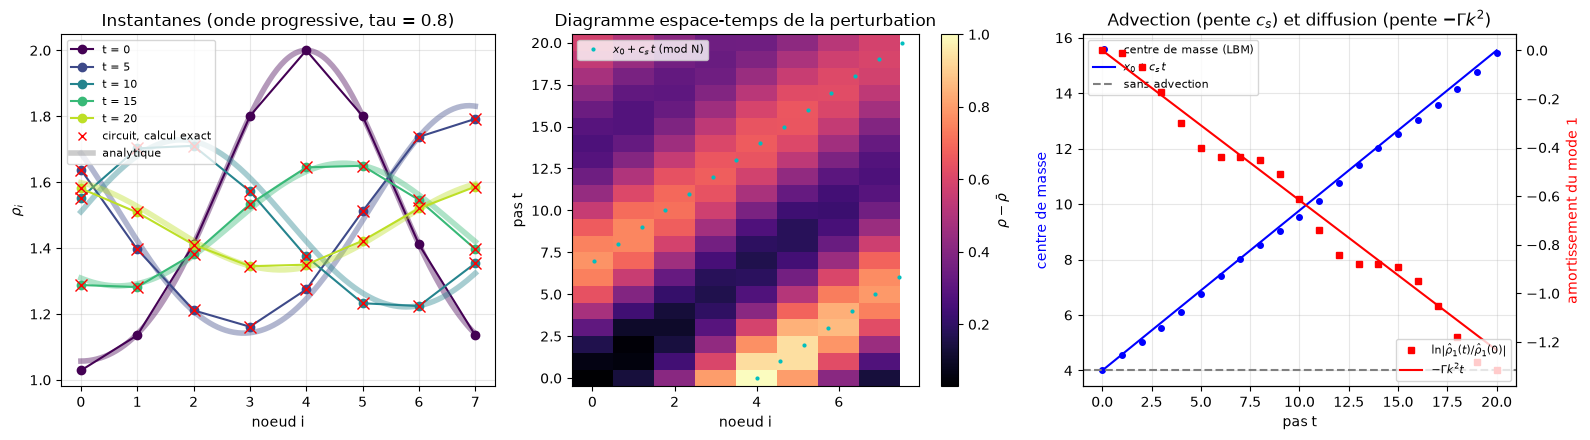

k = 2 pi / N = 0.785
vitesse     : mesuree 0.5714 | schema discret 0.5721 | Chapman-Enskog c_s = 0.5774
diffusion   : mesuree 0.1055 | schema discret 0.1018 | Chapman-Enskog Gamma = 0.1000


In [69]:
# evolution sur T_evol pas : LBM classique a chaque pas, circuit exact (statevector) a quelques instants
T_evol = 20
traj = [rho0]
f = f0.copy()
for _ in range(T_evol):
    f = lbm_step_loop(f)
    traj.append(f.sum(axis=0))
traj = np.array(traj)                       # (T_evol+1, N)
temps = np.arange(T_evol + 1)
instants = [0, 5, 10, 15, 20]
rho_q_inst = {t: run_quantum(F0, t, step, scale)[0] for t in instants[1:]}

# centre de masse de la perturbation (phase du mode de Fourier 1 ; le fond constant n'y contribue pas)
kx = 2*np.pi/N
mode1 = traj @ np.exp(-1j*kx*x)
centre = -np.unwrap(np.angle(mode1))/kx
amort = np.log(np.abs(mode1)/np.abs(mode1[0]))

# valeurs exactes du schema discret pour ce mode : valeurs propres de S(k) C_loc
Sk = np.diag([1, np.exp(1j*kx), np.exp(-1j*kx)])
lam = np.linalg.eigvals(Sk @ C_loc)
lam = lam[np.argsort(-np.abs(lam))][:2]            # les deux modes acoustiques
lam_d = lam[np.argmin(np.angle(lam))]              # celui qui va vers la droite
v_disc, G_disc = -np.angle(lam_d)/kx, -np.log(np.abs(lam_d))/kx**2

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

a = ax[0]
xf = np.linspace(0, N - 1, 200)
for t, col in zip(instants, plt.cm.viridis(np.linspace(0, 0.9, len(instants)))):
    a.plot(xf, rho_analytique(t, xx=xf), "-", color=col, alpha=0.4, lw=4)
    a.plot(x, traj[t], "o-", color=col, label=f"t = {t}")
    if t > 0:
        a.plot(x, rho_q_inst[t], "x", color="r", ms=8)
a.plot([], [], "x", color="r", label="circuit, calcul exact")
a.plot([], [], "-", color="gray", alpha=0.4, lw=4, label="analytique")
a.set_xlabel("noeud i"); a.set_ylabel(r"$\rho_i$"); a.legend(fontsize=8); a.grid(alpha=0.3)
a.set_title(f"Instantanes (onde progressive, tau = {tau})")

a = ax[1]
im = a.imshow(traj - rho_bar, origin="lower", aspect="auto", cmap="magma", extent=[-0.5, N - 0.5, -0.5, T_evol + 0.5])
a.plot((x0 + cs*temps) % N, temps, "c.", ms=4, label=r"$x_0 + c_s\,t$ (mod N)")
a.set_xlabel("noeud i"); a.set_ylabel("pas t"); a.legend(fontsize=8, loc="upper left")
fig.colorbar(im, ax=a, label=r"$\rho - \bar\rho$")
a.set_title("Diagramme espace-temps de la perturbation")

a = ax[2]
a.plot(temps, centre, "bo", ms=4, label="centre de masse (LBM)")
a.plot(temps, x0 + cs*temps, "b-", label=r"$x_0 + c_s\,t$")
a.axhline(x0, color="gray", ls="--", label="sans advection")
a.set_xlabel("pas t"); a.set_ylabel("centre de masse", color="b")
b = a.twinx()
b.plot(temps, amort, "rs", ms=4, label=r"$\ln|\hat\rho_1(t)/\hat\rho_1(0)|$")
b.plot(temps, -Gam*kx**2*temps, "r-", label=r"$-\Gamma k^2 t$")
b.set_ylabel("amortissement du mode 1", color="r")
a.legend(loc="upper left", fontsize=8); b.legend(loc="lower right", fontsize=8); a.grid(alpha=0.3)
a.set_title(r"Advection (pente $c_s$) et diffusion (pente $-\Gamma k^2$)")

plt.tight_layout(); plt.show()
print(f"k = 2 pi / N = {kx:.3f}")
print(f"vitesse     : mesuree {np.polyfit(temps, centre, 1)[0]:.4f} | schema discret {v_disc:.4f} | Chapman-Enskog c_s = {cs:.4f}")
print(f"diffusion   : mesuree {-np.polyfit(temps, amort, 1)[0]/kx**2:.4f} | schema discret {G_disc:.4f} | Chapman-Enskog Gamma = {Gam:.4f}")

### 7.2 Construction du circuit complet

- **Registres quantiques** : `pos` ($k=3$ qubits), `dir` (2 qubits), et **3 ancillas neuves par pas** (`anc0`, `anc1`, `anc2`).
  Mesurer toutes les ancillas à la fin revient au même que les mesurer après chaque pas (principe de la mesure différée), et ça permet à la simulation de tirer tous les *shots* d'un coup.
  Sur une vraie machine, on pourrait aussi mesurer puis réinitialiser (*reset*) un seul jeu d'ancillas à chaque pas : moins de qubits, même résultat.
- **Registres classiques** : `c_anc` (les mesures des ancillas) et `c_out` (la mesure finale de position + direction).
- Ordre : préparation de $|F^0\rangle$ → $T \times$ (collision FABLE sur `dir` + ancillas du pas, puis streaming $S$ sur `pos` + `dir`) → mesures.

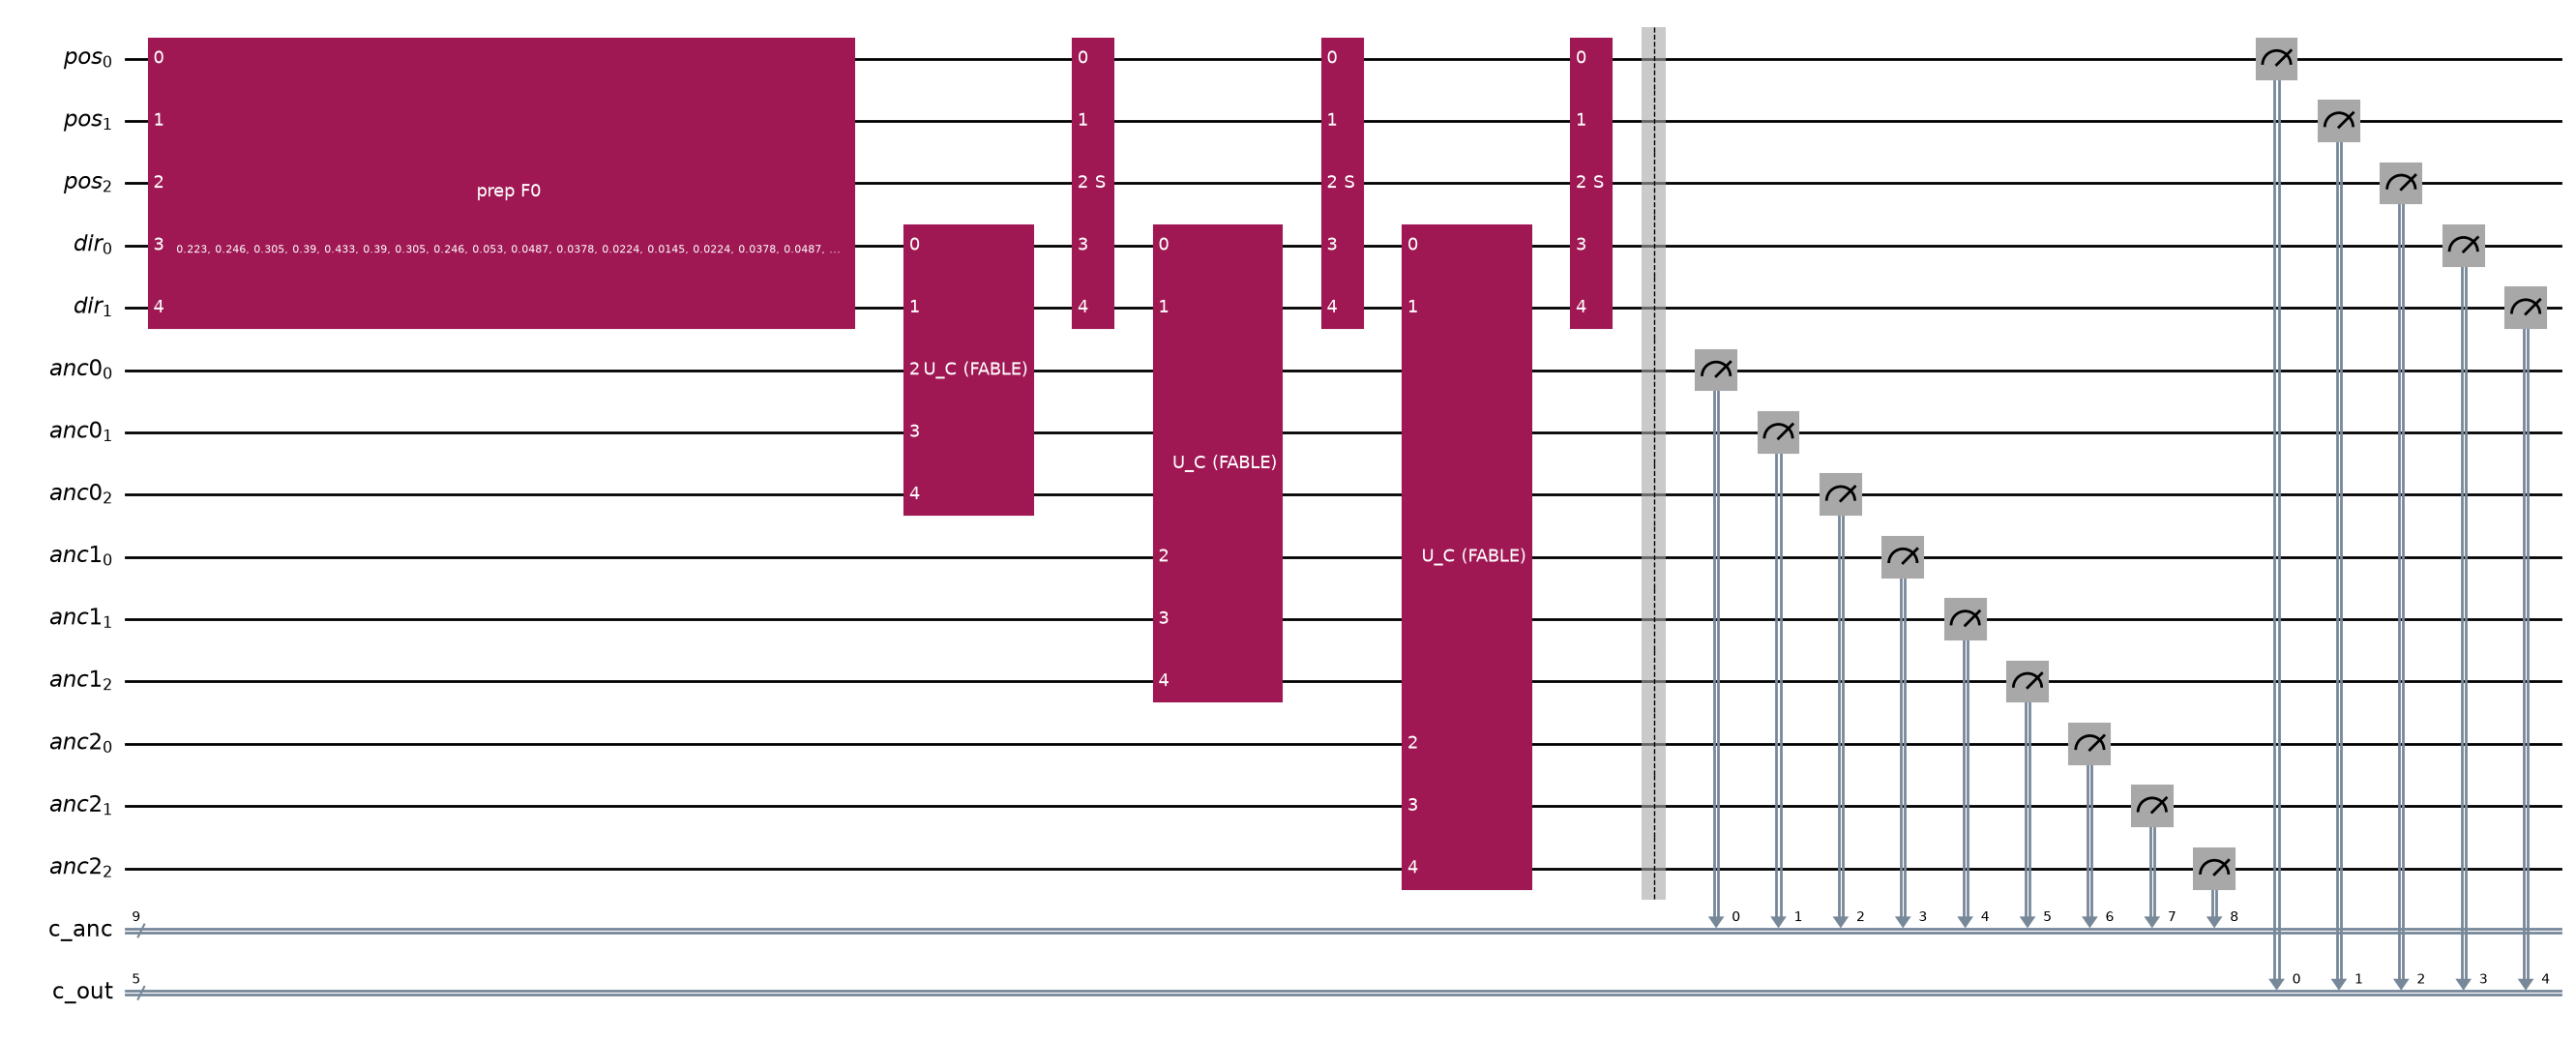

In [70]:
from qiskit import QuantumRegister, ClassicalRegister
from qiskit.circuit.library import StatePreparation
from qiskit_aer import AerSimulator

# F0 (onde progressive, R^{4N}) est defini en 7.1
masse = F0.sum()                                                    # conservee par le schema

pos_r = QuantumRegister(k, "pos")
dir_r = QuantumRegister(2, "dir")
anc_r = [QuantumRegister(n_anc, f"anc{t}") for t in range(steps)]
c_anc = ClassicalRegister(n_anc*steps, "c_anc")
c_out = ClassicalRegister(k + 2, "c_out")
full_circ = QuantumCircuit(pos_r, dir_r, *anc_r, c_anc, c_out)

prep_gate = StatePreparation(F0/np.linalg.norm(F0), label="prep F0")
coll_gate = circ_loc.to_gate(label="U_C (FABLE)")
stream_gate = circ_S.to_gate(label="S")

full_circ.append(prep_gate, list(pos_r) + list(dir_r))                  # 1) initialisation
for t in range(steps):                                                    # 2) T pas
    full_circ.append(coll_gate, list(dir_r) + list(anc_r[t]))
    full_circ.append(stream_gate, list(pos_r) + list(dir_r))
full_circ.barrier()
full_circ.measure([q for r in anc_r for q in r], c_anc)                   # 3) mesures
full_circ.measure(list(pos_r) + list(dir_r), c_out)

full_circ.draw("mpl", fold=-1)

### 7.3 Métriques du circuit : *width*, *depth*, portes

On compte sur le circuit **transpilé** en portes de base `cx` (CNOT) et `u` (rotation d'un qubit) : c'est ce qui compte sur une machine. On sépare le coût de chaque bloc.

In [71]:
def couts(qc):
    t = transpile(qc, basis_gates=["cx", "u", "measure", "reset"], optimization_level=1)
    ops = t.count_ops()
    return dict(
        qubits=t.num_qubits,
        depth=t.depth(lambda i: i.operation.name != "barrier"),
        depth_2q=t.depth(lambda i: i.operation.num_qubits == 2),
        cx=ops.get("cx", 0),
        u=ops.get("u", 0),
        gates=sum(v for kk, v in ops.items() if kk not in ("measure", "barrier")),
    )

def bloc(gate, nq):
    q = QuantumCircuit(nq); q.append(gate, range(nq)); return q

m_total = couts(full_circ)
m_prep = couts(bloc(prep_gate, k + 2))
m_coll = couts(circ_loc)
m_strm = couts(circ_S)

print("CIRCUIT COMPLET")
print(f"  width (largeur)       : {full_circ.num_qubits} qubits ({k} pos + 2 dir + {n_anc*steps} ancillas) et {full_circ.num_clbits} bits classiques")
print(f"  depth (profondeur)    : {m_total['depth']}")
print(f"  2-qubit depth         : {m_total['depth_2q']}")
print(f"  gates (portes)        : {m_total['gates']}  dont {m_total['cx']} CNOT et {m_total['u']} rotations u")
print(f"  mesures               : {full_circ.count_ops().get('measure', 0)}")
print()
print(f"{'bloc':28s}{'qubits':>7s}{'CNOT':>7s}{'portes':>8s}{'depth':>7s}{'x fois':>8s}{'CNOT total':>12s}")
for nom, m, nb in [("preparation de F0", m_prep, 1), ("collision U_C (FABLE)", m_coll, steps), ("streaming S", m_strm, steps)]:
    print(f"{nom:28s}{m['qubits']:>7d}{m['cx']:>7d}{m['gates']:>8d}{m['depth']:>7d}{nb:>8d}{m['cx']*nb:>12d}")

CIRCUIT COMPLET
  width (largeur)       : 14 qubits (3 pos + 2 dir + 9 ancillas) et 14 bits classiques
  depth (profondeur)    : 1641
  2-qubit depth         : 894
  gates (portes)        : 2003  dont 948 CNOT et 1055 rotations u
  mesures               : 14

bloc                         qubits   CNOT  portes  depth  x fois  CNOT total
preparation de F0                 5     26      57     53       1          26
collision U_C (FABLE)             5     22      42     36       3          66
streaming S                       5    314     659    583       3         942


### 7.4 Exécution avec des *shots*, post-sélection et reconstruction

1. On exécute le circuit `shots` fois sur `AerSimulator`.
2. On ne garde que les *shots* où **toutes** les ancillas valent 0.
3. La fréquence de chaque résultat $(a,i)$ estime $P(a,i) = f_{a,i}^2/\|F\|^2$. Les populations sont **positives** (vérifié en 7.1 grâce au fond $\bar\rho=1$), donc $f_{a,i} \propto \sqrt{P(a,i)}$. On renormalise par la masse (connue, conservée), puis $\rho_i = \sum_a f_{a,i}$.
   *Contrepartie du fond* : une partie des mesures porte sur le fond constant et non sur la perturbation.
4. Barres d'erreur ($\pm 1\sigma$, approximatives) : loi binomiale sur $P$, propagée à $\sqrt{P}$.

In [72]:
sim = AerSimulator(seed_simulator=1)
full_t = transpile(full_circ, sim)

def executer(shots):
    counts = sim.run(full_t, shots=shots).result().get_counts()
    P = np.zeros(D); garde = 0
    for cle, n in counts.items():
        bits_out, bits_anc = cle.split()            # registres affiches du dernier au premier
        if set(bits_anc) == {"0"}:                  # toutes les ancillas ont donne 0
            P[int(bits_out, 2)] += n; garde += n
    return P, garde

def reconstruire(P, garde):
    Ph = P/garde
    amp = np.sqrt(Ph)
    norm_f = masse/amp[:3*N].sum()
    F = amp*norm_f
    sig_P = np.sqrt(Ph*(1 - Ph)/garde)
    sig_F = np.where(amp > 0, sig_P/(2*np.maximum(amp, 1e-12)), 0)*norm_f
    rho = F[:N] + F[N:2*N] + F[2*N:3*N]
    sig_rho = np.sqrt(sig_F[:N]**2 + sig_F[N:2*N]**2 + sig_F[2*N:3*N]**2)
    return rho, sig_rho, Ph

shots = 24_000_000
P_mes, garde = executer(shots)
rho_shots, sig_rho, P_hat = reconstruire(P_mes, garde)

# probabilites exactes de sortie (apres post-selection), pour comparaison
sv = Statevector.from_instruction(full_circ.remove_final_measurements(inplace=False)).data
n_sys = k + 2
idx_ok = [j for j in range(len(sv)) if (j >> n_sys) == 0]          # ancillas toutes a 0
p_total_exact = sum(abs(sv[j])**2 for j in idx_ok)
P_exact = np.array([abs(sv[j])**2 for j in range(D)])/p_total_exact

err_shots = np.abs(rho_shots - rho_c)
print(f"shots                        : {shots:,}")
print(f"shots gardes (ancillas = 0)  : {garde:,}  ->  taux mesure {garde/shots:.2e}")
print(f"proba de succes exacte       : {p_total_exact:.2e}   (produit des {steps} pas : {np.prod(probs):.2e})")
print(f"shots a lancer par shot garde: {1/p_total_exact:,.0f}")
pic_pert = (rho_c - rho_bar).max()                 # amplitude de la perturbation (le fond ne porte pas la physique)
print(f"erreur max  |rho_shots - rho_LBM| : {err_shots.max():.3f}  ({100*err_shots.max()/pic_pert:.1f} % du pic de la perturbation rho - rho_bar)")
print(f"erreur L2 relative (perturbation) : {np.linalg.norm(rho_shots - rho_c)/np.linalg.norm(rho_c - rho_bar):.3f}")
print(f"incertitude statistique moyenne   : {sig_rho.mean():.3f}")
print(f"masse : initiale {rho0.sum():.4f} | LBM {rho_c.sum():.4f} | circuit {rho_shots.sum():.4f} (imposee a la reconstruction)")

shots                        : 24,000,000
shots gardes (ancillas = 0)  : 5,804  ->  taux mesure 2.42e-04
proba de succes exacte       : 2.41e-04   (produit des 3 pas : 2.41e-04)
shots a lancer par shot garde: 4,150
erreur max  |rho_shots - rho_LBM| : 0.032  (3.7 % du pic de la perturbation rho - rho_bar)
erreur L2 relative (perturbation) : 0.030
incertitude statistique moyenne   : 0.034
masse : initiale 11.7229 | LBM 11.7229 | circuit 11.7229 (imposee a la reconstruction)


### 7.5 Graphiques

1. **Solution** : circuit (*shots*, avec barres d'erreur), circuit exact, LBM classique et solution analytique.
2. **Probabilités mesurées vs exactes** pour chacun des $3N = 24$ états $(a, i)$.
3. **Probabilité de succès** cumulée pas après pas.
4. **Convergence statistique** : erreur en fonction du nombre de *shots* gardés (pente attendue $-1/2$).

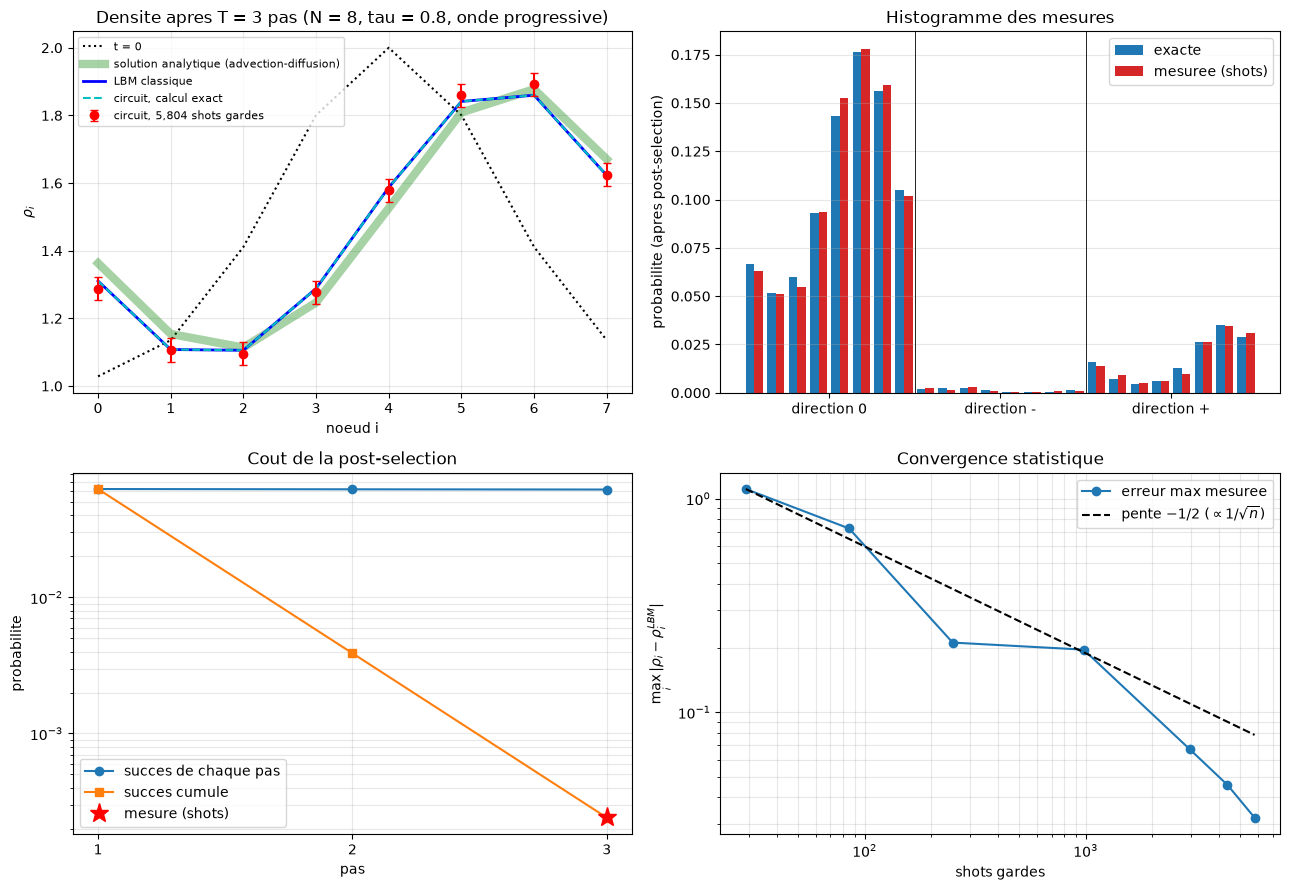

     100,000 shots ->     29 gardes -> erreur max 1.108
     300,000 shots ->     85 gardes -> erreur max 0.724
   1,000,000 shots ->    250 gardes -> erreur max 0.212
   4,000,000 shots ->    978 gardes -> erreur max 0.196
  12,000,000 shots ->  2,959 gardes -> erreur max 0.067
  18,000,000 shots ->  4,375 gardes -> erreur max 0.046
  24,000,000 shots ->  5,804 gardes -> erreur max 0.032


In [73]:
# convergence : plusieurs executions independantes
liste_shots = [100_000, 300_000, 1_000_000, 4_000_000, 12_000_000, 18_000_000, 24_000_000]
gardes, erreurs = [], []
for s_ in liste_shots:
    P_, g_ = executer(s_)
    r_, _, _ = reconstruire(P_, g_)
    gardes.append(g_); erreurs.append(np.abs(r_ - rho_c).max())

fig, ax = plt.subplots(2, 2, figsize=(13, 9))

a = ax[0, 0]
a.plot(x, rho0, "k:", label="t = 0")
a.plot(x, rho_th, "g-", lw=6, alpha=0.35, label="solution analytique (advection-diffusion)")
a.plot(x, rho_c, "b-", lw=2, label="LBM classique")
a.plot(x, rho_q_exact, "c--", lw=1.5, label="circuit, calcul exact")
a.errorbar(x, rho_shots, yerr=sig_rho, fmt="ro", capsize=3, label=f"circuit, {garde:,} shots gardes")
a.set_xlabel("noeud i"); a.set_ylabel(r"$\rho_i$"); a.grid(alpha=0.3); a.legend(fontsize=8)
a.set_title(f"Densite apres T = {steps} pas (N = {N}, tau = {tau}, onde progressive)")

a = ax[0, 1]
etats = np.arange(3*N)
a.bar(etats - 0.2, P_exact[:3*N], 0.4, label="exacte", color="tab:blue")
a.bar(etats + 0.2, P_hat[:3*N], 0.4, label="mesuree (shots)", color="tab:red")
for tt in (N, 2*N):
    a.axvline(tt - 0.5, color="k", lw=0.6)
a.set_xticks([N/2 - 0.5, 1.5*N - 0.5, 2.5*N - 0.5]); a.set_xticklabels(["direction 0", "direction -", "direction +"])
a.set_ylabel("probabilite (apres post-selection)"); a.legend(); a.grid(alpha=0.3, axis="y")
a.set_title("Histogramme des mesures")

a = ax[1, 0]
pas = np.arange(1, steps + 1)
a.semilogy(pas, probs, "o-", label="succes de chaque pas")
a.semilogy(pas, np.cumprod(probs), "s-", label="succes cumule")
a.semilogy([steps], [garde/shots], "r*", ms=14, label="mesure (shots)")
a.set_xticks(pas); a.set_xlabel("pas"); a.set_ylabel("probabilite"); a.grid(alpha=0.3, which="both"); a.legend()
a.set_title("Cout de la post-selection")

a = ax[1, 1]
g = np.array(gardes); e = np.array(erreurs)
a.loglog(g, e, "o-", label="erreur max mesuree")
a.loglog(g, e[0]*np.sqrt(g[0]/g), "k--", label=r"pente $-1/2$ ($\propto 1/\sqrt{n}$)")
a.set_xlabel("shots gardes"); a.set_ylabel(r"$\max_i |\rho_i - \rho_i^{LBM}|$"); a.grid(alpha=0.3, which="both"); a.legend()
a.set_title("Convergence statistique")

plt.tight_layout(); plt.show()

for s_, g_, e_ in zip(liste_shots, gardes, erreurs):
    print(f"{s_:>12,} shots -> {g_:>6,} gardes -> erreur max {e_:.3f}")

### 7.6 Bilan de la partie 7

- **Le circuit est exact** : en calcul exact (statevector), il reproduit le LBM d'advection-diffusion à $\sim10^{-14}$ près.
- **Physique** :
  - la perturbation est advectée à la vitesse mesurée $0{,}571$ (schéma discret $0{,}572$ ; Chapman-Enskog $c_s=0{,}577$) ;
  - elle diffuse avec un $\Gamma$ mesuré de $0{,}106$ (schéma discret $0{,}102$ ; Chapman-Enskog $0{,}100$) ;
  - les écarts à Chapman-Enskog, et l'écart LBM / solution analytique ($6\times10^{-2}$), viennent du développement en $k$ : sur 8 nœuds, $k=2\pi/N\approx0{,}79$ n'est pas petit. Ce n'est pas un effet quantique.
- **Probabilité de succès** :
  - elle vaut exactement $1/16$ au 1ᵉʳ pas. L'état initial est à l'équilibre ($Ef^0=f^0$), donc $Cf^0=f^0$ : la norme est conservée et le bloc FABLE vaut $C_{loc}/4$ ;
  - elle vaut ensuite $0{,}0622$ puis $0{,}0620$, soit $p_{tot}=2{,}41\times10^{-4}$. C'est le même ordre de grandeur qu'en diffusion pure.
- **Exécuté comme sur une machine**, le résultat devient **statistique** :
  - $4\,000\,000$ *shots* → 978 gardés ; erreur max $0{,}196$, soit $23\,\%$ du pic de la perturbation (erreur $L^2$ relative $0{,}16$) ;
  - l'erreur décroît comme $1/\sqrt{n_{gardes}}$ ($0{,}067$ avec 2 959 gardés).
- **Coût du fond $\bar\rho=1$** :
  - il est nécessaire pour avoir $f\ge0$ et reconstruire par $\sqrt{P}$ ;
  - mais la perturbation ne porte qu'environ un tiers de la masse ($3{,}7$ sur $11{,}7$). À nombre de *shots* gardés comparable, l'erreur relative sur la perturbation est donc plus grande qu'en diffusion pure ($\approx 7\,\%$).
- **Coût en portes** : identique au cas diffusif (14 qubits, profondeur 1641, 948 CNOT). Seule la matrice $C_{loc}$ change, pas la structure du circuit. Le streaming représente l'essentiel des CNOT.
- **Dilatation** (partie 8) : le succès passe à $\approx 55\,\%$ par pas.

## 8. Bonus : dilatation minimale (1 seul ancilla)

Avec $A = C_{loc,4}/\sigma_{\max}$ (donc $\|A\|\le1$), la matrice
$$U_{C} = \begin{pmatrix} A & \sqrt{I-AA^T} \\ \sqrt{I-A^TA} & -A^T \end{pmatrix}$$
est unitaire ($8\times8$, 3 qubits) et contient $A$ en haut à gauche. Facteur : $\sigma_{\max}\approx1.35$
au lieu de $4$.

In [74]:
sigma = np.linalg.svd(C_loc4, compute_uv=False)[0]
A = C_loc4/sigma
U_dil = np.block([[A, np.real(sl.sqrtm(np.eye(4) - A @ A.T))],
                  [np.real(sl.sqrtm(np.eye(4) - A.T @ A)), -A.T]])
print(f"sigma_max(C_loc) = {sigma:.4f}")
print("U_C unitaire :", np.allclose(U_dil @ U_dil.T, np.eye(8)))

circ_dil = QuantumCircuit(3, name="U_C")
circ_dil.append(UnitaryGate(U_dil, label="U_C"), [0, 1, 2])   # q0,q1 = direction, q2 = ancilla
t = transpile(circ_dil, basis_gates=['cx', 'u'], optimization_level=1)
print("portes apres transpilation :", dict(t.count_ops()))

step_dil = QuantumCircuit(k+3, name="pas LBM (dilatation)")
step_dil.compose(circ_dil, qubits=dirq + [k+2], inplace=True)
step_dil.compose(circ_S, qubits=pos + dirq, inplace=True)
print("bloc * sigma = S4 C4 :", np.allclose(sigma*Operator(step_dil).data[:D, :D], S4 @ C4))

rho_d, probs_d = run_quantum(F0, steps, step_dil, sigma)
print(f"max |rho - rho_classique| = {np.abs(rho_d - rho_c).max():.2e}")
print("probabilite par pas :", np.round(probs_d, 3))
print(f"cumulee sur {steps} pas : FABLE {np.prod(probs):.1e}  vs  dilatation {np.prod(probs_d):.1e}")

sigma_max(C_loc) = 1.3451
U_C unitaire : True
portes apres transpilation : {'u': 35, 'cx': 19}
bloc * sigma = S4 C4 : True
max |rho - rho_classique| = 1.38e-14
probabilite par pas : [0.553 0.55  0.548]
cumulee sur 3 pas : FABLE 2.4e-04  vs  dilatation 1.7e-01


/var/folders/bn/0v5ng2_j20q5rc92z31jyf7w0000gn/T/ipykernel_94040/2071116751.py:3: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  U_dil = np.block([[A, np.real(sl.sqrtm(np.eye(4) - A @ A.T))],


## Bilan

| Élément | Résultat |
|---|---|
| équilibre | ordre 1 avec $u=j/\rho$ recalculée : $f^{eq}=E\,f$ **linéaire** ; $C=C_{loc}\otimes I_N$, $C_{loc}=(1-\tfrac1\tau)I_3+E/\tau$  |
| physique | masse **et** flux conservés ; onde progressive $j=c_s\,\delta\rho$ : advection à $c_s$, diffusion $\Gamma=\tfrac12(1-c_s^2)(\tau-\tfrac12)$ |
| $C$ (non unitaire) | block-encodée par FABLE : bloc haut-gauche de $U$ = $C_4/(\alpha\,4N)$, $\alpha=1$, erreur $\sim10^{-15}$ |
| optimisation | FABLE sur $C_{loc}$ seul (5 qubits), facteur $4$ indépendant de $N$ |
| $S$ (unitaire) | inchangé par rapport à la diffusion ; circuit exact d'incréments contrôlés, **sans FABLE** |
| validation | circuit = LBM à $10^{-14}$ près ; LBM vs solution analytique : $6\times10^{-2}$ sur 8 nœuds (développement en $k$) |
| coût | 14 qubits, profondeur 1641, 948 CNOT ; succès $2{,}4\times10^{-4}$ sur 3 pas (FABLE), $0{,}17$ avec la dilatation |
| limites | fond $\bar\rho>0$ nécessaire pour $f\ge0$ ; vitesse d'advection fixée à $c_s$ par le réseau |

**Pistes pour la suite** :
- amplification d'amplitude pour réduire le coût de la post-sélection ;
- block-encoder directement plusieurs pas $(SC)^T$ ;
- pour une vitesse d'advection réglable : modèle à $u$ imposé (version sauvegardée dans `LBM_D1Q3_Advection_backup_u_impose.ipynb`).